# Griffiths et al. 2021 — Breast Cancer · 03 Signatures & Gate 2
Read the embryonic-module geography off the signature embeddings. **Gate 2**: is the pattern present — a Gast/pSom hub diverging into two arms (branching), OR a single (Gast/pSom)->Crest developmental gradient with organized cross-repression and a terminal Crest gradient (non-branching)? The non-branching case still passes (GO). Flag (but pass) if Crest enriches the Gast arm.

In [1]:
%matplotlib inline
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 91802 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 80/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography
Read the geography off the signature embeddings and the pseudotime gradient.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('raw module means (global strength):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
def _enr(A_,B_):
    az=(adata.obs[A_]-adata.obs[A_].mean())/adata.obs[A_].std()
    bz=(adata.obs[B_]-adata.obs[B_].mean())/adata.obs[B_].std()
    joint=((az>0.5)&(bz>0.5)).mean(); exp=(az>0.5).mean()*(bz>0.5).mean()
    return joint/exp if exp>0 else np.nan
print(f'joint pSom&Crest-high enrichment = {_enr("pSom","Crest"):.2f} (<1 = inverse terminal gradient)')
print(f'joint Gast&Crest-high enrichment = {_enr("Gast","Crest"):.2f} (>1 would mean Crest co-enriches the Gast pole)')
print(f'joint Gast&pSom-high enrichment = {_enr("Gast","pSom"):.2f}')
crest_flag = _enr('Gast','Crest') > _enr('pSom','Crest')
print('Gate 2: organized Gast/pSom cross-repression (r=-0.45) + single (pSom origin)->Crest terminal gradient '
      '-> GO (non-branching)')
print('Gate 3: no bifurcation (0 forks) -> NA')
print('Crest-arm flag:', 'Crest tracks the Gast pole (flagged, pass anyway)' if crest_flag else 'Crest terminal, opposes pSom most (no inversion)')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.45
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.62
raw module means (global strength): {'Gast': -0.02, 'pSom': -0.053, 'Crest': 0.0159}
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.011
  pSom_sm: rho = -0.654
  Crest_sm: rho = +0.565
Neural-crest-high decile mean pseudotime = 0.85 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.31 (<1 = inverse terminal gradient)
joint Gast&Crest-high enrichment = 0.33 (>1 would mean Crest co-enriches the Gast pole)
joint Gast&pSom-high enrichment = 0.80
Gate 2: organized Gast/pSom cross-repression (r=-0.45) + single (pSom origin)->Crest terminal gradient -> GO (non-branching)
Gate 3: no bifurcation (0 forks) -> NA
Crest-arm flag: Crest tracks the Gast pole (flagged, pass anyway)


### Figures — signature embeddings (raw scores) + external colorbars
Raw `score_genes` values shown on the house linear layout (not the graph-smoothed scores used for reading relationships).

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-1-c30d2b89c7d6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-1-c30d2b89c7d6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-1-c30d2b89c7d6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)


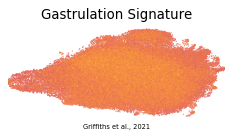

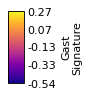

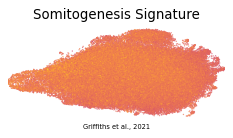

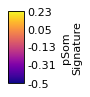

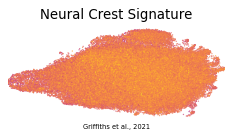

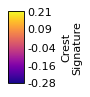

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
    plt.show()

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (91802, 21353)
